# AI4I 2020 Predictive Maintenance: EDA and Baseline Models

**Capstone phase 0: the model spine.**

This notebook takes the AI4I 2020 dataset from raw CSV to a calibrated failure classifier ready to sit behind the FastAPI endpoint. It covers:

1. EDA, including the leakage trap and a label consistency check
2. Feature engineering driven by the failure physics (`temp_delta`, `power`)
3. A logistic regression baseline (the honest floor)
4. Gradient boosting with class weighting (the workhorse)
5. Evaluation that respects the 3% class imbalance: PR curves, threshold selection, calibration
6. Saving the model artifact for the API

**Data:** place `ai4i2020.csv` in `data/`. Download from the UCI ML Repository (AI4I 2020 Predictive Maintenance Dataset) or Kaggle (search "ai4i2020").

Reference: Matzka, S. (2020). AI4I 2020 Predictive Maintenance Dataset. UCI Machine Learning Repository. https://doi.org/10.24432/C5HS5C

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             classification_report, confusion_matrix)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (9, 4.5)

## 1. Load and first look

In [2]:
df = pd.read_csv("../data/ai4i2020.csv")
print(df.shape)
df.head()

(10000, 12)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Type                     10000 non-null  str    
 1   Air temperature [K]      10000 non-null  float64
 2   Process temperature [K]  10000 non-null  float64
 3   Rotational speed [rpm]   10000 non-null  int64  
 4   Torque [Nm]              10000 non-null  float64
 5   Tool wear [min]          10000 non-null  int64  
 6   Machine failure          10000 non-null  int64  
 7   TWF                      10000 non-null  int64  
 8   HDF                      10000 non-null  int64  
 9   PWF                      10000 non-null  int64  
 10  OSF                      10000 non-null  int64  
 11  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(8), str(1)
memory usage: 937.6 KB


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.0,0.0,0.0,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.0,0.0,0.0,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.0,0.0,0.0,1.0
OSF,10000.0,0.00980,0.098514,0.0,0.0,0.0,0.0,1.0


### Class balance

This is the number that shapes everything downstream. Expect roughly 3.4% failures in the real dataset.

Failures: 339 of 10000 (3.39%)


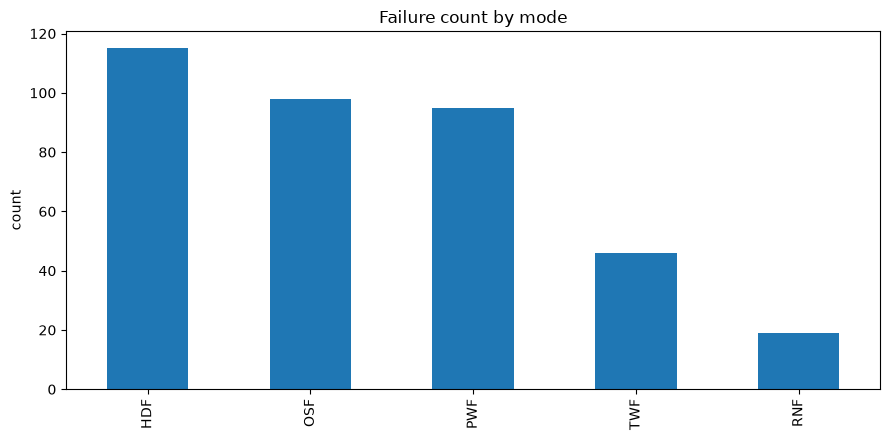

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

In [4]:
target_rate = df["Machine failure"].mean()
print(f"Failures: {df['Machine failure'].sum()} of {len(df)} ({target_rate:.2%})")

mode_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]
mode_counts = df[mode_cols].sum().sort_values(ascending=False)
ax = mode_counts.plot.bar(title="Failure count by mode")
ax.set_ylabel("count")
plt.tight_layout(); plt.show()
mode_counts

### Label consistency check

A known quirk of this dataset: the `Machine failure` flag and the five mode columns do not align perfectly in a handful of rows. We quantify it here rather than discovering it later. Rows flagged as failure with no mode set, or vice versa, are worth knowing about (RNF rows in particular behave oddly in the published data).

In [5]:
any_mode = df[mode_cols].any(axis=1)
fail = df["Machine failure"].astype(bool)

fail_no_mode = (fail & ~any_mode).sum()
mode_no_fail = (~fail & any_mode).sum()
print(f"Failure flagged but no mode set : {fail_no_mode}")
print(f"Mode set but not flagged failure: {mode_no_fail}")

Failure flagged but no mode set : 9
Mode set but not flagged failure: 18


### Sensor distributions by outcome

Where do failures live in each sensor's range? Overlaid histograms give the intuition that the engineered features will formalize.

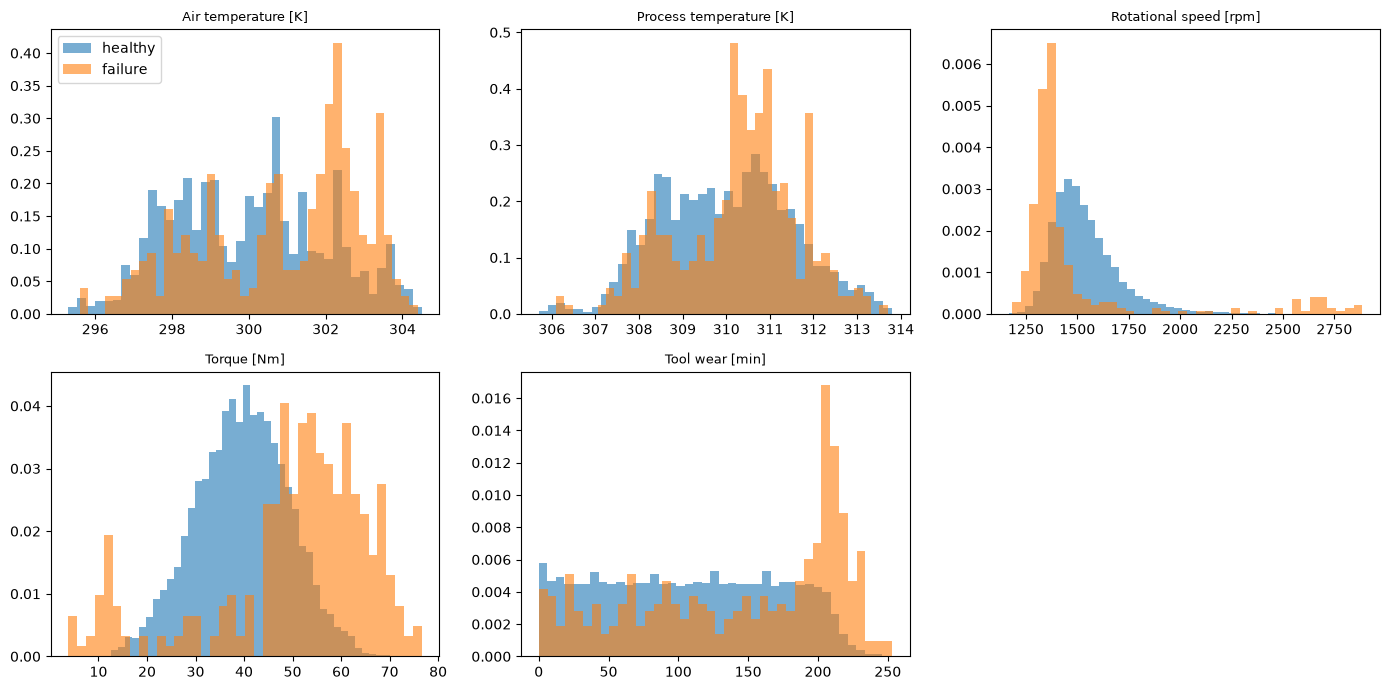

In [6]:
sensor_cols = ["Air temperature [K]", "Process temperature [K]",
               "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), sensor_cols):
    ax.hist(df.loc[~fail, col], bins=40, alpha=0.6, label="healthy", density=True)
    ax.hist(df.loc[fail, col], bins=40, alpha=0.6, label="failure", density=True)
    ax.set_title(col, fontsize=9)
axes.ravel()[-1].axis("off")
axes[0, 0].legend()
plt.tight_layout(); plt.show()

## 2. Feature engineering

Two rules and two features.

**Rule 1, the leakage trap:** the five mode columns (TWF, HDF, PWF, OSF, RNF) *define* the target. They never enter the feature matrix. A model trained with them scores near-perfectly and knows nothing.

**Rule 2:** `UDI` and `Product ID` are identifiers. The ID's letter prefix duplicates `Type`; the number is a row index. Dropped.

**The engineered features** hand the model the failure physics directly:

- `temp_delta` = process temp minus air temp. Heat dissipation failures occur when this gap is small at low speed.
- `power` = torque x angular velocity (watts). Power failures occur outside a safe band.

Trees can find interactions on their own, but giving them the physically meaningful combinations makes the model better *and* explainable: the model watches the same physics a good machinist feels.

In [7]:
data = df.copy()
data["temp_delta"] = data["Process temperature [K]"] - data["Air temperature [K]"]
data["power"] = data["Torque [Nm]"] * data["Rotational speed [rpm]"] * 2 * np.pi / 60  # watts

DROP = ["UDI", "Product ID", "Machine failure"] + mode_cols
FEATURES = [col for col in data.columns if col not in DROP]
CAT = ["Type"]
NUM = [f for f in FEATURES if f not in CAT]

X = data[FEATURES]
y = data["Machine failure"]
print(FEATURES)

['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'temp_delta', 'power']


## 3. Split

Stratified, so the rare class is proportionally represented in both sets. 75/25.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"train: {len(X_train)} ({y_train.mean():.2%} failures)")
print(f"test : {len(X_test)} ({y_test.mean():.2%} failures)")

train: 7500 (3.39% failures)
test : 2500 (3.40% failures)


## 4. Baseline: logistic regression

The honest floor. `class_weight='balanced'` reweights the loss so the 3% class matters; scaling because logistic regression cares about feature magnitudes. If gradient boosting cannot beat this meaningfully, it has not earned its complexity.

In [9]:
prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first"), CAT),
])

logreg = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=2000,
                               random_state=RANDOM_STATE)),
])
logreg.fit(X_train, y_train)
p_lr = logreg.predict_proba(X_test)[:, 1]
ap_lr = average_precision_score(y_test, p_lr)
print(f"Logistic regression PR-AUC: {ap_lr:.3f}")

Logistic regression PR-AUC: 0.439


## 5. Gradient boosting

`HistGradientBoostingClassifier`: fast on CPU (part of the edge story), handles the categorical column natively, and carves out the interaction regions where the failure modes live (temp_delta AND low speed, wear TIMES torque).

In [10]:
X_train_gb = X_train.copy(); X_test_gb = X_test.copy()
X_train_gb["Type"] = X_train_gb["Type"].astype("category")
X_test_gb["Type"] = X_test_gb["Type"].astype("category")

gb = HistGradientBoostingClassifier(
    class_weight="balanced",
    categorical_features="from_dtype",
    random_state=RANDOM_STATE,
)
gb.fit(X_train_gb, y_train)
p_gb = gb.predict_proba(X_test_gb)[:, 1]
ap_gb = average_precision_score(y_test, p_gb)
print(f"Gradient boosting PR-AUC: {ap_gb:.3f}  (baseline was {ap_lr:.3f})")

Gradient boosting PR-AUC: 0.899  (baseline was 0.439)


## 6. Evaluation the imbalance-honest way

Accuracy is meaningless here (predicting "never fails" scores ~96.6%). We use precision-recall curves and PR-AUC, then choose an operating threshold from the business asymmetry: a missed failure (scrap, downtime, emergency repair) costs far more than a false alarm (a tech checks a healthy machine).

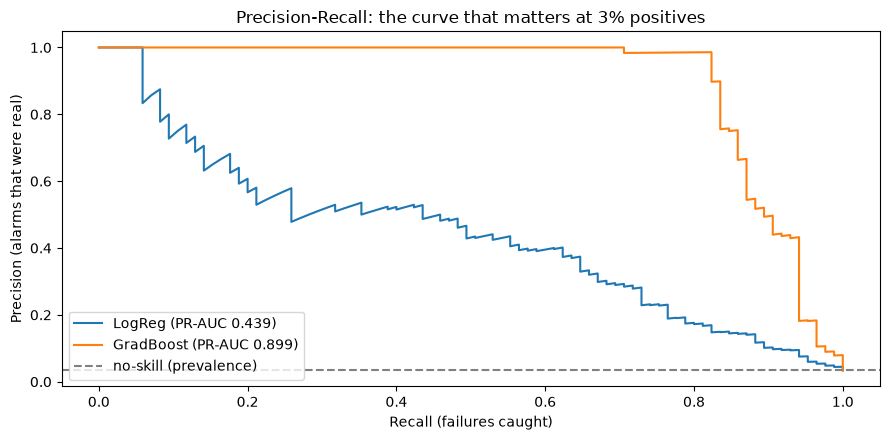

In [11]:
fig, ax = plt.subplots()
for name, p, ap in [("LogReg", p_lr, ap_lr), ("GradBoost", p_gb, ap_gb)]:
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, label=f"{name} (PR-AUC {ap:.3f})")
ax.axhline(y_test.mean(), ls="--", c="gray", label="no-skill (prevalence)")
ax.set_xlabel("Recall (failures caught)"); ax.set_ylabel("Precision (alarms that were real)")
ax.set_title("Precision-Recall: the curve that matters at 3% positives")
ax.legend(); plt.tight_layout(); plt.show()

### Choosing the operating threshold

Strategy: target ~90% recall (catch nine of ten failures), then report what that costs in false alarms per 1,000 cycles. The threshold is a business decision expressed in math, and it ships with the model artifact.

In [12]:
prec, rec, thr = precision_recall_curve(y_test, p_gb)
TARGET_RECALL = 0.90
# rec is decreasing along thr; find last threshold where recall >= target
valid = np.where(rec[:-1] >= TARGET_RECALL)[0]
idx = valid[-1] if len(valid) else 0
threshold = thr[idx]

pred = (p_gb >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
fa_per_1000 = 1000 * fp / len(y_test)

print(f"Threshold          : {threshold:.3f}")
print(f"Recall             : {tp/(tp+fn):.2%}  ({tp} of {tp+fn} failures caught)")
print(f"Precision          : {tp/(tp+fp):.2%}")
print(f"False alarms       : {fp} ({fa_per_1000:.1f} per 1,000 cycles)")
print()
print(classification_report(y_test, pred, target_names=["healthy", "failure"]))

Threshold          : 0.046
Recall             : 90.59%  (77 of 85 failures caught)
Precision          : 49.68%
False alarms       : 78 (31.2 per 1,000 cycles)

              precision    recall  f1-score   support

     healthy       1.00      0.97      0.98      2415
     failure       0.50      0.91      0.64        85

    accuracy                           0.97      2500
   macro avg       0.75      0.94      0.81      2500
weighted avg       0.98      0.97      0.97      2500



### Calibration

The dashboard will display these probabilities. A gauge reading 80% should mean readings like this failed about 80% of the time historically. The reliability curve checks that; if it bows badly, wrap the model in `CalibratedClassifierCV` (isotonic) before shipping.

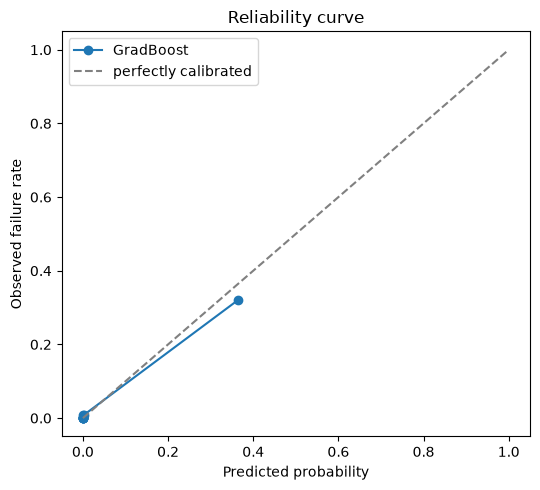

In [13]:
frac_pos, mean_pred = calibration_curve(y_test, p_gb, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(mean_pred, frac_pos, "o-", label="GradBoost")
ax.plot([0, 1], [0, 1], "--", c="gray", label="perfectly calibrated")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed failure rate")
ax.set_title("Reliability curve"); ax.legend(); plt.tight_layout(); plt.show()

## 7. What is the model looking at?

Permutation importance on the test set. Expect the engineered features and tool wear near the top; that agreement with mechanical intuition is a presentation slide, not just a diagnostic.

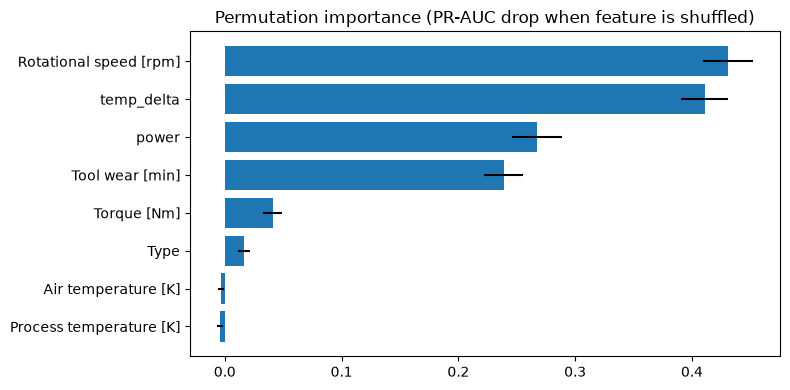

In [14]:
imp = permutation_importance(gb, X_test_gb, y_test, n_repeats=10,
                             random_state=RANDOM_STATE, scoring="average_precision")
order = imp.importances_mean.argsort()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(np.array(X_test_gb.columns)[order], imp.importances_mean[order],
        xerr=imp.importances_std[order])
ax.set_title("Permutation importance (PR-AUC drop when feature is shuffled)")
plt.tight_layout(); plt.show()

## 8. Ship it

Save the fitted model, the chosen threshold, and the feature list as one artifact. `predict.py` in the API loads exactly this file; the feature list keeps the API and the model honest about column order.

In [15]:
artifact = {
    "model": gb,
    "threshold": float(threshold),
    "features": list(X_train_gb.columns),
    "categorical": CAT,
    "model_version": "gb-v0.1",
    "pr_auc_test": float(ap_gb),
}
joblib.dump(artifact, "../models/failure_model_v0.1.joblib")
print("saved ../models/failure_model_v0.1.joblib")

saved ../models/failure_model_v0.1.joblib


## Next steps

- Hyperparameter tuning with `RandomizedSearchCV` optimizing average precision (same workflow as the Kaggle competition)
- SMOTE comparison cell: does synthetic oversampling beat class weights here, or just add machinery?
- `CalibratedClassifierCV` wrapper if the reliability curve warrants it
- Isolation Forest anomaly layer (stretch goal), trained on healthy cycles only
- Promote this notebook's final pipeline into `backend/app/ml/train.py`

In [16]:
from sklearn.metrics import classification_report, confusion_matrix

threshold = artifact["threshold"]
print("threshold:", threshold)

proba = gb.predict_proba(X_test_gb)[:, 1]
pred = (proba >= threshold).astype(int)
print(classification_report(y_test, pred, digits=3))
print(confusion_matrix(y_test, pred))

threshold: 0.04560714026166542
              precision    recall  f1-score   support

           0      0.997     0.968     0.982      2415
           1      0.497     0.906     0.642        85

    accuracy                          0.966      2500
   macro avg      0.747     0.937     0.812      2500
weighted avg      0.980     0.966     0.970      2500

[[2337   78]
 [   8   77]]
